# 00. Vector Operations & Gradient Descent Basics
### Linear Algebra Foundations for Machine Learning with an Ice Cream Sales Demo

In machine learning and data science, algorithms rarely operate on individual numbers one by one. Instead, data points, features, predictions, and model parameters are organized into **vectors** and **matrices**.

Using vector operations—a practice known as **vectorization**—gives us two massive advantages:
1. **Mental clarity:** Equations in code look nearly identical to mathematical formulas.
2. **Speed & Efficiency:** NumPy executes vectorized vector operations in optimized C/Fortran and parallel hardware, running hundreds of times faster than Python `for` loops.

---

### Notebook Roadmap:
- **Part 1: Vector Fundamentals for Gradient Descent**
  - What is a vector? (1D arrays, shapes, dimensions)
  - Vector Transpose: Row vectors vs. Column vectors
  - Vector arithmetic: Scaling by a scalar, vector addition/subtraction, broadcasting
  - Vector multiplication: **Element-wise multiplication** vs. **The Dot Product**
  - Why the dot product is the mathematical engine of Gradient Descent
- **Part 2: Step-by-Step Gradient Descent Demo (Ice Cream Sales)**
  - Introducing the Ice Cream Sales vs. Temperature dataset
  - Step 1: Defining the Linear Model Hypothesis ($f_{w,b}(x) = w x + b$)
  - Step 2: Formulating the Mean Squared Error (MSE) Cost Function with vector dot products
  - Step 3: Computing Gradients ($\partial J / \partial w$ and $\partial J / \partial b$) using vectorization
  - Step 4: Walking through a single manual update step
  - Step 5: Implementing the full Gradient Descent training loop
  - Step 6: Visualizing learning curves and model line convergence
  - Step 7: Making real-world predictions and interpreting model parameters

In [1]:
# Step 1: Import core scientific libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configure clean, high-resolution plotting defaults
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10
plt.rcParams['figure.figsize'] = (7, 4.5)

print("Libraries imported successfully!")
print(f"NumPy version : {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Libraries imported successfully!
NumPy version : 2.5.3
Pandas version: 3.0.6


---
# Part 1: Vector Fundamentals for Gradient Descent

## Section 1: What is a Vector?

In machine learning:
- A **scalar** is a single number (e.g., learning rate $\alpha = 0.01$, temperature $T = 25$).
- A **vector** is an ordered 1-dimensional list of numbers.
  - A feature vector might represent temperatures across different days: $\mathbf{x} = [0, 5, 10, 15, \dots]$.
  - A target vector might represent sales: $\mathbf{y} = [5, 8, 16, 19, \dots]$.
  - A parameter vector might represent model weights: $\mathbf{w} = [w_1, w_2]$.

Geometrically, a vector represents a direction and magnitude in space, starting from the origin $(0, 0)$.

In [2]:
# Creating 1D vectors in NumPy
v = np.array([3.0, 7.0, 2.0])

print(f"Vector v            : {v}")
print(f"Shape of v          : {v.shape}  -> 1D array with 3 elements")
print(f"Number of dimensions: {v.ndim}")
print(f"Data type           : {v.dtype}")
print(f"Length len(v)       : {len(v)}")

Vector v            : [3. 7. 2.]
Shape of v          : (3,)  -> 1D array with 3 elements
Number of dimensions: 1
Data type           : float64
Length len(v)       : 3


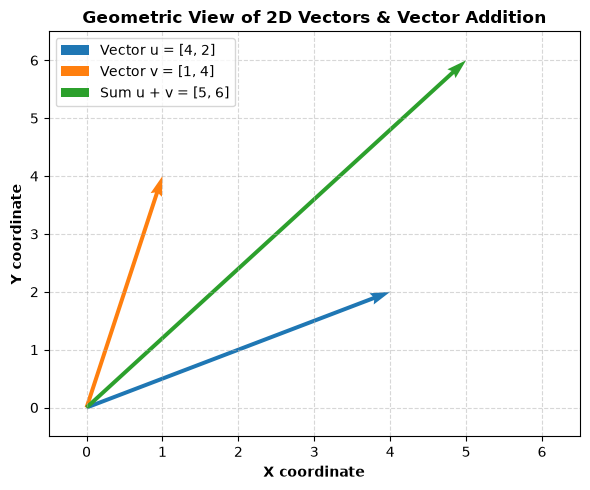

In [3]:
# Visualizing 2D vectors geometrically as arrows from origin (0, 0)
u_vec = np.array([4, 2])
v_vec = np.array([1, 4])
sum_vec = u_vec + v_vec

fig, ax = plt.subplots(figsize=(6, 5))

# Plot vector arrows
ax.quiver(0, 0, u_vec[0], u_vec[1], angles='xy', scale_units='xy', scale=1, color='#1f77b4', label='Vector u = [4, 2]')
ax.quiver(0, 0, v_vec[0], v_vec[1], angles='xy', scale_units='xy', scale=1, color='#ff7f0e', label='Vector v = [1, 4]')
ax.quiver(0, 0, sum_vec[0], sum_vec[1], angles='xy', scale_units='xy', scale=1, color='#2ca02c', label='Sum u + v = [5, 6]')

# Grid and styling
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(-0.5, 6.5)
ax.set_xlabel('X coordinate', fontweight='bold')
ax.set_ylabel('Y coordinate', fontweight='bold')
ax.set_title('Geometric View of 2D Vectors & Vector Addition', fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

## Section 2: Vector Shapes, Row vs. Column Vectors & Transpose

In linear algebra:
- A **Column Vector** has shape $(m \times 1)$:
  $$\mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \\ x_3 \end{bmatrix}$$
- A **Row Vector** has shape $(1 \times m)$:
  $$\mathbf{x}^T = \begin{bmatrix} x_1 & x_2 & x_3 \end{bmatrix}$$

The **Transpose** operation (denoted by superscript $T$) flips rows into columns and columns into rows.

### Important NumPy Note:
- A standard 1D NumPy array `np.array([1, 2, 3])` has shape `(3,)`. It is **flat** (neither strictly a row nor a column).
- Transposing a 1D array with `.T` does not change its shape—it is still `(3,)`.
- To create a true 2D column vector, we reshape it to `(m, 1)` using `.reshape(-1, 1)`. Transposing it then produces a `(1, m)` row vector!

In [4]:
# 1D array vs Column Vector vs Row Vector in NumPy
a = np.array([2.0, 5.0, 8.0])
print("1. Standard 1D NumPy Array:")
print("   a       :", a)
print("   shape   :", a.shape)
print("   a.T     :", a.T, " (1D transpose leaves shape unchanged)\n")

# Explicit Column Vector: shape (3, 1)
col_vec = a.reshape(-1, 1)
print("2. Column Vector (3 x 1):")
print(col_vec)
print("   shape   :", col_vec.shape, "\n")

# Transpose of Column Vector -> Row Vector: shape (1, 3)
row_vec = col_vec.T
print("3. Row Vector after Transpose col_vec.T (1 x 3):")
print(row_vec)
print("   shape   :", row_vec.shape)

1. Standard 1D NumPy Array:
   a       : [2. 5. 8.]
   shape   : (3,)
   a.T     : [2. 5. 8.]  (1D transpose leaves shape unchanged)

2. Column Vector (3 x 1):
[[2.]
 [5.]
 [8.]]
   shape   : (3, 1) 

3. Row Vector after Transpose col_vec.T (1 x 3):
[[2. 5. 8.]]
   shape   : (1, 3)


## Section 3: Vector Arithmetic (Scaling, Subtraction & Broadcasting)

Gradient descent relies on three basic vector arithmetic operations:

### 1. Scalar Multiplication
Multiplying a vector by a single number scales every entry:
$$\alpha \mathbf{v} = [\alpha v_1, \alpha v_2, \dots, \alpha v_m]$$
*In Gradient Descent:* Used to scale parameter updates by the learning rate $\alpha$:
$$\text{step} = \alpha \cdot \frac{\partial J}{\partial w}$$

### 2. Vector Subtraction & Addition
Element-wise subtraction of two vectors of identical shape:
$$\mathbf{a} - \mathbf{b} = [a_1 - b_1, a_2 - b_2, \dots, a_m - b_m]$$
*In Gradient Descent:* Used to compute the **error vector** between predictions and actual targets:
$$\mathbf{e} = \hat{\mathbf{y}} - \mathbf{y}$$

### 3. Broadcasting with Scalars
When we add a scalar (single number) $b$ to a vector $\mathbf{z}$, NumPy automatically "broadcasts" $b$ to every element:
$$[z_1, z_2, z_3] + b = [z_1 + b, z_2 + b, z_3 + b]$$
*In Linear Regression:* Used to compute linear model predictions with bias $b$:
$$\hat{\mathbf{y}} = w \mathbf{x} + b$$

In [5]:
# Demonstration of Arithmetic & Broadcasting
# Simulated sample data
x_sample = np.array([10.0, 20.0, 30.0])
y_actual = np.array([15.0, 26.0, 38.0])

# Current trial parameters
w = 1.2
b = 2.0

# 1. Broadcasting: w * x multiplies each element by 1.2, then + b adds 2.0 to each
y_pred = w * x_sample + b
print(f"Inputs x            : {x_sample}")
print(f"Predictions y_pred  : {w} * x + {b} = {y_pred}")

# 2. Vector Subtraction: Prediction errors (e = y_pred - y_actual)
errors = y_pred - y_actual
print(f"Actual targets y    : {y_actual}")
print(f"Error vector (e)    : {errors}  (positive means over-prediction, negative means under-prediction)")

# 3. Scalar Multiplication: Scaling gradient by learning rate alpha
alpha = 0.001
dj_dw = -140.0
param_step = alpha * dj_dw
print(f"Update step size    : alpha * dj_dw = {alpha} * ({dj_dw}) = {param_step}")

Inputs x            : [10. 20. 30.]
Predictions y_pred  : 1.2 * x + 2.0 = [14. 26. 38.]
Actual targets y    : [15. 26. 38.]
Error vector (e)    : [-1.  0.  0.]  (positive means over-prediction, negative means under-prediction)
Update step size    : alpha * dj_dw = 0.001 * (-140.0) = -0.14


## Section 4: Vector Multiplication (Element-Wise vs. Dot Product)

This is the most critical distinction in all of machine learning linear algebra!

### 1. Element-Wise Multiplication (Hadamard Product)
- **Math Symbol:** $\mathbf{a} \odot \mathbf{b}$
- **Python / NumPy:** `a * b`
- Multiplies corresponding elements one-by-one. The output is **another vector** of the same length:
  $$[a_1, a_2, \dots, a_m] \odot [b_1, b_2, \dots, b_m] = [a_1 b_1, a_2 b_2, \dots, a_m b_m]$$
- *Application in Regression:* Squaring errors element-wise: $\mathbf{e}^2 = [e_1^2, e_2^2, \dots, e_m^2]$.

---

### 2. The Dot Product (Inner Product)
- **Math Symbol:** $\mathbf{a} \cdot \mathbf{b}$ or $\mathbf{a}^T \mathbf{b}$
- **Python / NumPy:** `np.dot(a, b)` or `a @ b`
- Multiplies corresponding elements **AND sums them up**. The output is a **single scalar number**:
  $$\mathbf{a} \cdot \mathbf{b} = \sum_{i=1}^m a_i b_i = a_1 b_1 + a_2 b_2 + \dots + a_m b_m$$

---

### Why the Dot Product is the Engine of Gradient Descent:

1. **Sum of Squared Errors (Cost Function):**
   $$\sum_{i=1}^m e_i^2 = e_1^2 + e_2^2 + \dots + e_m^2 = \mathbf{e} \cdot \mathbf{e}$$
   Therefore, Mean Squared Error is simply:
   $$J(w, b) = \frac{1}{m} (\mathbf{e} \cdot \mathbf{e})$$

2. **Weight Gradient (Slope derivative):**
   The derivative of cost with respect to slope $w$ is:
   $$\frac{\partial J}{\partial w} = \frac{2}{m} \sum_{i=1}^m e_i x_i = \frac{2}{m} (\mathbf{e} \cdot \mathbf{x})$$
   Instead of writing a slow `for` loop over all data samples, we write **one single vectorized line**:
   `dj_dw = (2 / m) * np.dot(errors, x)`!

In [6]:
# Comparing Element-Wise Multiplication vs. Dot Product
u = np.array([2.0, 3.0, 4.0])
v = np.array([5.0, 10.0, 2.0])

# 1. Element-wise Multiplication (u * v)
elem_mult = u * v
print(f"Vector u                     : {u}")
print(f"Vector v                     : {v}")
print(f"Element-wise (u * v)         : {elem_mult}  -> Shape: {elem_mult.shape} (Vector)")

# 2. Dot Product (Inner Product)
dot_prod = np.dot(u, v)
at_prod = u @ v  # '@' is Python's matrix/vector multiplication operator

print(f"Dot product np.dot(u, v)     : {dot_prod}  -> Scalar number (2*5 + 3*10 + 4*2 = 10 + 30 + 8 = 48)")
print(f"Dot product with '@' operator: {at_prod}  -> Exact same result")

# 3. Dot product of a vector with itself: sum of squares!
sum_sq_dot = np.dot(u, u)
sum_sq_loop = np.sum(u ** 2)
print(f"Dot product np.dot(u, u)     : {sum_sq_dot}  -> 2^2 + 3^2 + 4^2 = 4 + 9 + 16 = 29")
print(f"Matches sum(u ** 2)          : {sum_sq_loop}")

Vector u                     : [2. 3. 4.]
Vector v                     : [ 5. 10.  2.]
Element-wise (u * v)         : [10. 30.  8.]  -> Shape: (3,) (Vector)
Dot product np.dot(u, v)     : 48.0  -> Scalar number (2*5 + 3*10 + 4*2 = 10 + 30 + 8 = 48)
Dot product with '@' operator: 48.0  -> Exact same result
Dot product np.dot(u, u)     : 29.0  -> 2^2 + 3^2 + 4^2 = 4 + 9 + 16 = 29
Matches sum(u ** 2)          : 29.0


### Summary of Vector Operations for Machine Learning

| Operation | Mathematical Notation | NumPy Code | Output Type | Machine Learning Role |
| :--- | :--- | :--- | :--- | :--- |
| **Vector Definition** | $\mathbf{x} = [x_1, \dots, x_m]^T$ | `x = np.array([...])` | 1D Array $(m,)$ | Feature or target dataset |
| **Column Reshape** | $\mathbf{x} \in \mathbb{R}^{m \times 1}$ | `x.reshape(-1, 1)` | 2D Array $(m, 1)$ | Standard matrix representation |
| **Transpose** | $\mathbf{x}^T \in \mathbb{R}^{1 \times m}$ | `col_vec.T` | 2D Array $(1, m)$ | Aligning dimensions for multiplication |
| **Scalar Scaling** | $\alpha \mathbf{v}$ | `alpha * v` | 1D Array $(m,)$ | Learning rate step: $\alpha \nabla J$ |
| **Vector Subtraction** | $\mathbf{e} = \hat{\mathbf{y}} - \mathbf{y}$ | `errors = y_hat - y` | 1D Array $(m,)$ | Residual errors of prediction |
| **Broadcasting** | $\hat{\mathbf{y}} = w \mathbf{x} + b$ | `y_hat = w * x + b` | 1D Array $(m,)$ | Linear model predictions |
| **Element-Wise Prod** | $\mathbf{a} \odot \mathbf{b}$ | `a * b` | 1D Array $(m,)$ | Pointwise transformations |
| **Dot Product** | $\mathbf{a} \cdot \mathbf{b} = \sum a_i b_i$ | `np.dot(a, b)` or `a @ b` | Scalar | **MSE cost** $\mathbf{e} \cdot \mathbf{e}$ & **Gradient** $\mathbf{e} \cdot \mathbf{x}$ |

---
# Part 2: Step-by-Step Gradient Descent Demo (Ice Cream Sales)

Now that we have mastered the necessary vector operations, let's put them to work on a real-world dataset.

### The Dataset: Ice Cream Sales vs. Temperature

A beachside kiosk tracked average daily temperatures ($^\circ\text{C}$) and ice cream sales (units sold):

| Avg Temp ($^\circ\text{C}$) - $x$ | Sales (units) - $y$ |
| :---: | :---: |
| 0 | 5 |
| 5 | 8 |
| 10 | 16 |
| 15 | 19 |
| 20 | 30 |
| 25 | 35 |
| 30 | 30 |
| 35 | 43 |
| 40 | 41 |
| 45 | 44 |
| 50 | 34 |

Our goal is to **train a linear regression model from scratch** using Gradient Descent to discover the relationship between temperature and sales!

In [7]:
# Load the ice cream sales data from CSV (saved in data/ice_cream_sales.csv)
df = pd.read_csv('data/ice_cream_sales.csv')

# Extract features (x) and targets (y) as float 1D NumPy vectors
x = df['temperature_c'].values.astype(float)
y = df['sales'].values.astype(float)
m = len(y)  # Number of training samples

print(f"Total training samples (m): {m}")
print(f"Temperature vector x (°C) : {x}")
print(f"Sales vector y (units)     : {y}")
print("\nDataset summary statistics:")
print(df.describe().round(1))

Total training samples (m): 11
Temperature vector x (°C) : [ 0.  5. 10. 15. 20. 25. 30. 35. 40. 45. 50.]
Sales vector y (units)     : [ 5.  8. 16. 19. 30. 35. 30. 43. 41. 44. 34.]

Dataset summary statistics:
       temperature_c  sales
count           11.0   11.0
mean            25.0   27.7
std             16.6   13.8
min              0.0    5.0
25%             12.5   17.5
50%             25.0   30.0
75%             37.5   38.0
max             50.0   44.0


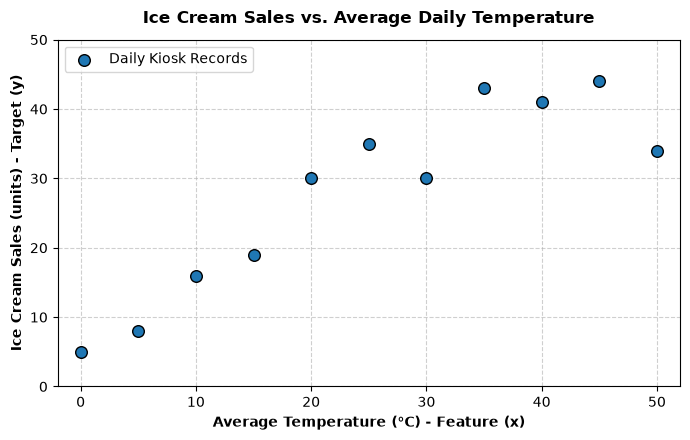

In [8]:
# Visualizing the Raw Data: Temperature vs. Sales
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.scatter(x, y, color='#1f77b4', s=70, edgecolor='black', linewidth=1, zorder=3, label='Daily Kiosk Records')

ax.set_title('Ice Cream Sales vs. Average Daily Temperature', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Average Temperature (°C) - Feature (x)', fontweight='bold')
ax.set_ylabel('Ice Cream Sales (units) - Target (y)', fontweight='bold')
ax.set_xlim(-2, 52)
ax.set_ylim(0, 50)
ax.grid(True, linestyle='--', alpha=0.6, zorder=0)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

## Section 6: Step 1 - The Linear Model Hypothesis

We model the relationship between temperature $x$ and ice cream sales $y$ with a straight line:

$$f_{w,b}(x) = w x + b$$

where:
- $x$ is the temperature in $^\circ\text{C}$ (input feature).
- $\hat{y} = f_{w,b}(x)$ is the predicted ice cream sales (target).
- $w$ is the **weight / slope**: Expected extra ice creams sold per $1^\circ\text{C}$ increase in temperature.
- $b$ is the **bias / intercept**: Expected baseline ice creams sold when temperature is freezing ($0^\circ\text{C}$).

Thanks to NumPy's **broadcasting**, evaluating all $m$ predictions takes just one line:
`y_hat = w * x + b`

In [9]:
# Step 1: Vectorized prediction function
def predict(x, w, b):
    # Compute predictions: y_hat = w * x + b
    return w * x + b

# Let's test with an initial baseline guess of w = 0, b = 0
w_init = 0.0
b_init = 0.0
y_hat_initial = predict(x, w_init, b_init)

print(f"Inputs x (temperatures)        : {x}")
print(f"Predictions with (w={w_init}, b={b_init}) : {y_hat_initial}")
print(f"Actual sales targets y         : {y}")

Inputs x (temperatures)        : [ 0.  5. 10. 15. 20. 25. 30. 35. 40. 45. 50.]
Predictions with (w=0.0, b=0.0) : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Actual sales targets y         : [ 5.  8. 16. 19. 30. 35. 30. 43. 41. 44. 34.]


## Section 7: Step 2 - The Cost Function (Mean Squared Error)

To train our model, we need a mathematical score that measures how "wrong" our current $(w, b)$ guesses are. We use the standard **Mean Squared Error (MSE)**:

$$J(w, b) = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})^2$$

Using our vector tools from Part 1:
1. Compute the error vector: $\mathbf{e} = \hat{\mathbf{y}} - \mathbf{y}$ (`errors = y_hat - y`)
2. Sum of squared errors is the dot product: $\sum e_i^2 = \mathbf{e} \cdot \mathbf{e}$ (`np.dot(errors, errors)`)
3. Divide by $m$: `cost = (1 / m) * np.dot(errors, errors)`

In [10]:
# Step 2: Vectorized Cost Function
def compute_cost(x, y, w, b):
    # J(w, b) = (1 / m) * sum((y_hat - y)^2) = (1 / m) * dot(e, e)
    m = len(y)
    y_hat = predict(x, w, b)
    errors = y_hat - y
    
    # Vectorized computation using dot product
    cost = (1 / m) * np.dot(errors, errors)
    return cost

# Compute initial cost
initial_cost = compute_cost(x, y, w_init, b_init)
print(f"Initial Cost J(w=0, b=0): {initial_cost:.4f}")

# Double check that np.mean(errors ** 2) yields the exact same answer:
errors_init = y_hat_initial - y
print(f"Verified via np.mean()  : {np.mean(errors_init ** 2):.4f}")

Initial Cost J(w=0, b=0): 941.1818
Verified via np.mean()  : 941.1818


## Section 8: Step 3 - Computing Gradients (Direction of Steepest Ascent)

To reduce the cost $J(w, b)$, we need to know:
- Does increasing $w$ increase or decrease the cost?
- Does increasing $b$ increase or decrease the cost?

Calculus gives us the partial derivatives (gradients):

$$\frac{\partial J}{\partial w} = \frac{2}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)}) x^{(i)} = \frac{2}{m} (\mathbf{e} \cdot \mathbf{x})$$

$$\frac{\partial J}{\partial b} = \frac{2}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)}) = \frac{2}{m} \sum_{i=1}^{m} e_i$$

### Intuition:
- **Gradient for $w$:** $\mathbf{e} \cdot \mathbf{x}$ multiplies each error by its temperature.
  - If we underestimate sales on hot days ($e < 0$ and $x$ is large), $\mathbf{e} \cdot \mathbf{x}$ will be strongly negative.
  - Moving in the *opposite* direction of the gradient ($-\alpha \frac{\partial J}{\partial w}$) will therefore **increase $w$**!
- **Gradient for $b$:** The average error. If on average predictions are too low, the sum of errors is negative, telling gradient descent to **increase $b$**.

In [11]:
# Step 3: Vectorized Gradient Function
def compute_gradient(x, y, w, b):
    # dj_dw = (2 / m) * dot(errors, x)
    # dj_db = (2 / m) * sum(errors)
    m = len(y)
    y_hat = predict(x, w, b)
    errors = y_hat - y
    
    # Vectorized gradient calculations
    dj_dw = (2 / m) * np.dot(errors, x)
    dj_db = (2 / m) * np.sum(errors)
    
    return dj_dw, dj_db

dj_dw_0, dj_db_0 = compute_gradient(x, y, w_init, b_init)
print(f"Gradient w.r.t w (dj_dw) at (0, 0): {dj_dw_0:.4f}")
print(f"Gradient w.r.t b (dj_db) at (0, 0): {dj_db_0:.4f}")

Gradient w.r.t w (dj_dw) at (0, 0): -1760.9091
Gradient w.r.t b (dj_db) at (0, 0): -55.4545


## Section 9: Step 4 - A Single Manual Update (Under the Hood)

The **Gradient Descent Update Rule** updates parameters simultaneously:

$$w \leftarrow w - \alpha \frac{\partial J}{\partial w}$$

$$b \leftarrow b - \alpha \frac{\partial J}{\partial b}$$

where $\alpha$ is the **learning rate** (step size).

Let's trace **Iteration 1** by hand in code with $\alpha = 0.001$:

In [12]:
# Step 4: Trace a single manual gradient descent update
alpha = 0.001  # Chosen learning rate

# Current state (Iteration 0)
print("=== Iteration 0 (Initial Guess) ===")
print(f"w = {w_init:.4f},  b = {b_init:.4f}")
print(f"Cost J(w, b) = {initial_cost:.4f}")
print(f"Gradients    : dj_dw = {dj_dw_0:.4f}, dj_db = {dj_db_0:.4f}")

# Compute parameter updates
w_step1 = w_init - alpha * dj_dw_0
b_step1 = b_init - alpha * dj_db_0
cost_step1 = compute_cost(x, y, w_step1, b_step1)

print("\n=== Iteration 1 (After 1 Simultaneous Step) ===")
print(f"w_new = {w_init:.4f} - ({alpha} * {dj_dw_0:.4f}) = {w_step1:.4f}")
print(f"b_new = {b_init:.4f} - ({alpha} * {dj_db_0:.4f}) = {b_step1:.4f}")
print(f"New Cost J(w_new, b_new) = {cost_step1:.4f}")
print(f"Cost reduction in 1 step : {initial_cost - cost_step1:.4f}  (Cost went down dramatically!)")

=== Iteration 0 (Initial Guess) ===
w = 0.0000,  b = 0.0000
Cost J(w, b) = 941.1818
Gradients    : dj_dw = -1760.9091, dj_db = -55.4545

=== Iteration 1 (After 1 Simultaneous Step) ===
w_new = 0.0000 - (0.001 * -1760.9091) = 1.7609
b_new = 0.0000 - (0.001 * -55.4545) = 0.0555
New Cost J(w_new, b_new) = 555.3921
Cost reduction in 1 step : 385.7897  (Cost went down dramatically!)


## Section 10: Step 5 - The Gradient Descent Training Loop

Now that we understand each individual step, let's assemble the complete training loop to run for multiple iterations until the cost converges to its minimum.

In [13]:
# Step 5: Full Gradient Descent Training Function
def gradient_descent(x, y, w_init, b_init, alpha, num_iters):
    # Run Batch Gradient Descent to find optimal (w, b)
    w = w_init
    b = b_init
    cost_history = []
    snapshots = []
    
    snapshot_iters = {0, 1, 10, 50, 100, 500, 1000, 3000, 5000, 10000}
    
    for i in range(num_iters + 1):
        # 1. Evaluate current cost
        cost = compute_cost(x, y, w, b)
        cost_history.append(cost)
        
        # Save snapshot for inspection
        if i in snapshot_iters:
            snapshots.append((i, w, b, cost))
            
        # 2. Compute gradients
        dj_dw, dj_db = compute_gradient(x, y, w, b)
        
        # 3. Simultaneous update
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        
    return w, b, cost_history, snapshots

# Train model for 10,000 iterations
alpha = 0.001
num_iters = 10000

w_opt, b_opt, cost_history, snapshots = gradient_descent(
    x, y, w_init=0.0, b_init=0.0, alpha=alpha, num_iters=num_iters
)

print(f"Optimization finished in {num_iters} iterations!")
print(f"Optimal slope (w*)     : {w_opt:.4f}  (ice creams per °C)")
print(f"Optimal intercept (b*) : {b_opt:.4f}  (base ice creams at 0°C)")
print(f"Minimum MSE Cost       : {cost_history[-1]:.4f}")

Optimization finished in 10000 iterations!
Optimal slope (w*)     : 0.7499  (ice creams per °C)
Optimal intercept (b*) : 8.9703  (base ice creams at 0°C)
Minimum MSE Cost       : 32.0961


In [14]:
# Inspect the progression of parameters during training
snapshot_df = pd.DataFrame(snapshots, columns=['Iteration', 'Weight (w)', 'Bias (b)', 'Cost J(w,b)'])
print("Training Milestones:")
print(snapshot_df.to_string(index=False))

Training Milestones:
 Iteration  Weight (w)  Bias (b)  Cost J(w,b)
         0    0.000000  0.000000   941.181818
         1    1.760909  0.055455   555.392104
        10    0.946325  0.078180    57.749026
        50    0.998277  0.281300    53.814652
       100    0.991263  0.526753    52.608994
       500    0.941803  2.257278    45.085671
      1000    0.893932  3.932229    39.433669
      3000    0.795310  7.382874    32.843038
      5000    0.763839  8.483975    32.171948
     10000    0.749939  8.970318    32.096119


## Section 11: Visualizing the Gradient Descent Process

Let's create three clear visual plots to understand how gradient descent learned:
1. **The Learning Curve:** Cost $J(w, b)$ steadily dropping over iterations.
2. **Line Evolution:** Watching the regression line rotate and shift to fit the data points.
3. **The Final Best-Fit Line with Residual Errors:** Visualizing the differences between actual sales and model predictions.

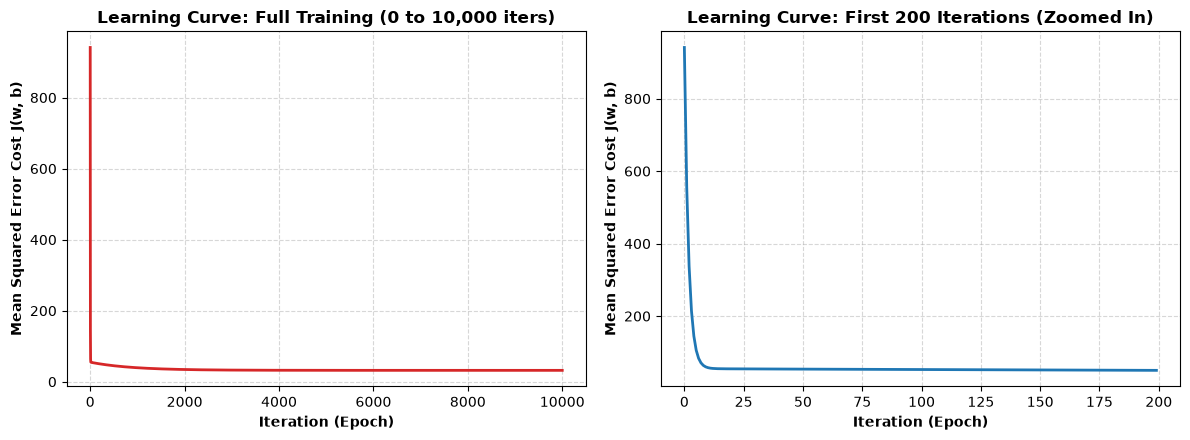

In [15]:
# Visual 1: Learning Curve (Cost vs. Iterations)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Full 10,000 iterations
ax1.plot(cost_history, color='#d62728', linewidth=2)
ax1.set_title('Learning Curve: Full Training (0 to 10,000 iters)', fontweight='bold')
ax1.set_xlabel('Iteration (Epoch)', fontweight='bold')
ax1.set_ylabel('Mean Squared Error Cost J(w, b)', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# Zoomed in to first 200 iterations (showing rapid early descent)
ax2.plot(cost_history[:200], color='#1f77b4', linewidth=2)
ax2.set_title('Learning Curve: First 200 Iterations (Zoomed In)', fontweight='bold')
ax2.set_xlabel('Iteration (Epoch)', fontweight='bold')
ax2.set_ylabel('Mean Squared Error Cost J(w, b)', fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

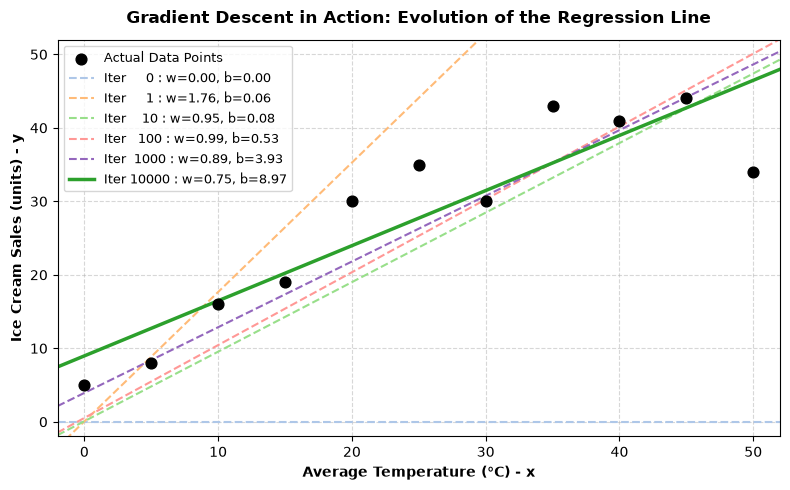

In [16]:
# Visual 2: Evolution of the Regression Line Across Milestones
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the raw data points
ax.scatter(x, y, color='black', s=60, zorder=5, label='Actual Data Points')

# Generate smooth x values for line plotting
x_line = np.linspace(-2, 52, 100)

# Selected milestones to plot
milestones_to_plot = [0, 1, 10, 100, 1000, 10000]
colors = ['#aec7e8', '#ffbb78', '#98df8a', '#ff9896', '#9467bd', '#2ca02c']

for (it, w_val, b_val, c_val), col in zip([s for s in snapshots if s[0] in milestones_to_plot], colors):
    line_style = '--' if it < 10000 else '-'
    line_width = 1.5 if it < 10000 else 2.5
    ax.plot(x_line, w_val * x_line + b_val, linestyle=line_style, linewidth=line_width, 
            color=col, label=f'Iter {it:5d} : w={w_val:.2f}, b={b_val:.2f}')

ax.set_title('Gradient Descent in Action: Evolution of the Regression Line', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Average Temperature (°C) - x', fontweight='bold')
ax.set_ylabel('Ice Cream Sales (units) - y', fontweight='bold')
ax.set_xlim(-2, 52)
ax.set_ylim(-2, 52)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

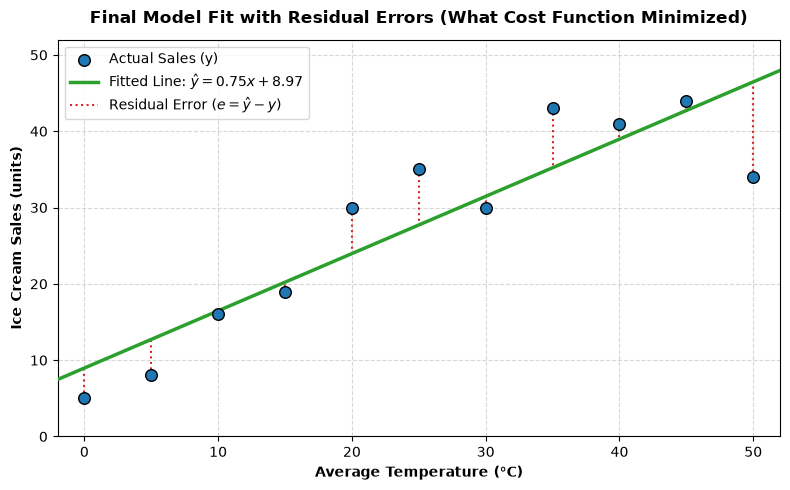

In [17]:
# Visual 3: Final Fitted Model with Residuals (Errors)
fig, ax = plt.subplots(figsize=(8, 5))

# 1. Plot raw data
ax.scatter(x, y, color='#1f77b4', s=70, edgecolor='black', zorder=4, label='Actual Sales (y)')

# 2. Plot final regression line
y_line_final = predict(x_line, w_opt, b_opt)
ax.plot(x_line, y_line_final, color='#2ca02c', linewidth=2.5, zorder=3,
        label=f'Fitted Line: $\hat{{y}} = {w_opt:.2f}x + {b_opt:.2f}$')

# 3. Draw vertical dashed error lines (residuals) for each data point
y_hat_final = predict(x, w_opt, b_opt)
for xi, yi, y_pred_i in zip(x, y, y_hat_final):
    ax.plot([xi, xi], [yi, y_pred_i], color='#d62728', linestyle=':', linewidth=1.5, zorder=2)
# Dummy entry for legend
ax.plot([], [], color='#d62728', linestyle=':', label='Residual Error ($e = \hat{y} - y$)')

ax.set_title('Final Model Fit with Residual Errors (What Cost Function Minimized)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Average Temperature (°C)', fontweight='bold')
ax.set_ylabel('Ice Cream Sales (units)', fontweight='bold')
ax.set_xlim(-2, 52)
ax.set_ylim(0, 52)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

## Section 12: Making Real-World Predictions & Interpreting the Model

### 1. Model Interpretation:
Our trained model equation is:

$$\hat{y} = 0.75 \cdot x + 8.97$$

- **Slope ($w = 0.75$):** For every $1^\circ\text{C}$ increase in temperature, ice cream sales increase by an average of **0.75 units** (or roughly **7.5 extra ice creams per $10^\circ\text{C}$**).
- **Intercept ($b = 8.97$):** On a freezing day ($0^\circ\text{C}$), base expected sales are approximately **9 ice creams**.

---

### 2. Predicting Sales on Unseen Temperatures:
Let's use our vectorized model to predict sales for temperatures not in our original dataset:
- A cool spring morning: $12^\circ\text{C}$
- A warm pleasant afternoon: $22^\circ\text{C}$
- A hot summer day: $32^\circ\text{C}$
- A very hot heatwave: $42^\circ\text{C}$

In [18]:
# Vectorized predictions on new temperatures
new_temps = np.array([12.0, 22.0, 32.0, 42.0])
predicted_sales = predict(new_temps, w_opt, b_opt)

print("=" * 55)
print("    PREDICTING ICE CREAM SALES FOR NEW TEMPERATURES")
print("=" * 55)
for temp, sales_pred in zip(new_temps, predicted_sales):
    print(f"Temperature: {temp:4.1f} °C  -->  Predicted Sales: {sales_pred:5.1f} ice creams")
print("=" * 55)

    PREDICTING ICE CREAM SALES FOR NEW TEMPERATURES
Temperature: 12.0 °C  -->  Predicted Sales:  18.0 ice creams
Temperature: 22.0 °C  -->  Predicted Sales:  25.5 ice creams
Temperature: 32.0 °C  -->  Predicted Sales:  33.0 ice creams
Temperature: 42.0 °C  -->  Predicted Sales:  40.5 ice creams


In [19]:
# Verification with Analytical Solution (Ordinary Least Squares / np.polyfit)
# In simple linear regression, the closed-form formula (Normal Equation) solves for optimal w and b directly
w_exact, b_exact = np.polyfit(x, y, deg=1)

print("Comparison: Gradient Descent vs. Analytical Solution")
print("-" * 55)
print(f"Gradient Descent Solution : w = {w_opt:.4f},  b = {b_opt:.4f}")
print(f"Analytical Exact Solution : w = {w_exact:.4f},  b = {b_exact:.4f}")
print(f"Absolute Difference       : |diff_w| = {abs(w_opt - w_exact):.4f}, |diff_b| = {abs(b_opt - b_exact):.4f}")
print("-" * 55)
print("Gradient Descent successfully found the exact optimal solution!")

Comparison: Gradient Descent vs. Analytical Solution
-------------------------------------------------------
Gradient Descent Solution : w = 0.7499,  b = 8.9703
Analytical Exact Solution : w = 0.7491,  b = 9.0000
Absolute Difference       : |diff_w| = 0.0008, |diff_b| = 0.0297
-------------------------------------------------------
Gradient Descent successfully found the exact optimal solution!


## Section 13: Key Takeaways & What Comes Next

### What We Learned in This Notebook:
1. **Vectors in Machine Learning:** Vectors organize features (temperature $\mathbf{x}$) and targets (sales $\mathbf{y}$) for batch processing.
2. **Transpose & Shapes:** Transposing allows alignment of matrix/vector dimensions for inner products.
3. **Element-wise vs. Dot Product:**
   - `a * b` performs element-by-element multiplication.
   - `np.dot(a, b)` (or `a @ b`) multiplies and sums, computing sums of squared errors $\mathbf{e} \cdot \mathbf{e}$ and parameter gradients $\mathbf{e} \cdot \mathbf{x}$ in one single line.
4. **The 4 Steps of Gradient Descent:**
   - **Predict:** $\hat{\mathbf{y}} = w \mathbf{x} + b$
   - **Measure Cost:** $J(w, b) = \frac{1}{m} (\mathbf{e} \cdot \mathbf{e})$
   - **Compute Gradients:** $\frac{\partial J}{\partial w} = \frac{2}{m}(\mathbf{e} \cdot \mathbf{x})$ and $\frac{\partial J}{\partial b} = \frac{2}{m}\sum e_i$
   - **Simultaneous Update:** $w \leftarrow w - \alpha \frac{\partial J}{\partial w}$, $b \leftarrow b - \alpha \frac{\partial J}{\partial b}$

---

### Where to Go Next in the Regression Series:
- **`01_cost_function_viz.ipynb`:** Explore the 3D bowl-shaped Cost Surface $J(w, b)$ and contour plots.
- **`02_gradient_descent_x_square.ipynb`:** Build visual intuition for learning rates and step sizes on $f(x) = x^2$.
- **`03_gradient_descent_one_var.ipynb`:** Apply univariate linear regression to Qatar apartment rental listings.
- **`04_gradient_descent_multi_var.ipynb`:** Scale from 1 feature to multiple features using full Matrix-Vector multiplication!